# Weather, Match Outcomes, and Home Advantage

**Research question:** How are weather conditions at kick-off associated with football match outcomes and home advantage, and do these associations differ between the Premier League, Bundesliga, and La Liga?

This notebook analyzes 3,197 completed matches (subject to the current data file). It combines exploratory analysis, statistical tests, temporal out-of-season model evaluation, and an exploratory weather clustering. The analysis describes associations; it does **not** establish causality.

**Important:** Run the notebook from top to bottom. The latest available season is held out for testing; all models use the same split.


In [1]:
# If packages are missing, run once in a separate cell: %pip install pandas numpy matplotlib seaborn scipy scikit-learn
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, kruskal
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay, roc_auc_score, silhouette_score
)
from sklearn.cluster import KMeans

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
RANDOM_STATE = 42

# Prefer the repository data folder; also allow running beside the CSV.
path_candidates = [
    Path("data/spiele_roh_with_weather.csv"),
    Path("../data/spiele_roh_with_weather.csv"),
    Path("spiele_roh_with_weather.csv"),
]
DATA_PATH = next((p for p in path_candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find spiele_roh_with_weather.csv. Put it in data/ or next to this notebook."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns from {DATA_PATH}")
display(df.head())


Loaded 3,198 rows and 28 columns from data/spiele_roh_with_weather.csv


,match_id,liga,saison,spieltag,anstoss_utc,status,heim_id,heim_team,gast_id,gast_team,tore_heim,tore_gast,resultat,stadium,city,country,latitude,longitude,regen_summe,temperatur_mittel,wind_mittel,snowfall_summe,cloud_cover_mittel,apparent_temp_mittel,humidity_mittel,surface_pressure_mittel,pressure_msl_mittel,wind_gusts_mittel
0,435943,Premier League,2023/24,1,2023-08-11T19:00:00Z,FINISHED,328,Burnley FC,65,Manchester City FC,0,3,A,Turf Moor,Burnley,England,53.80000,-2.23333,0.0,16.37,14.17,0.0,25.33,14.63,70.67,995.93,1012.73,29.63
1,435944,Premier League,2023/24,1,2023-08-12T12:00:00Z,FINISHED,57,Arsenal FC,351,Nottingham Forest FC,2,1,H,Emirates Stadium,London,England,51.50853,-0.12574,0.2,20.40,31.07,0.0,60.33,17.13,64.67,1011.20,1013.90,54.40
2,435945,Premier League,2023/24,1,2023-08-12T14:00:00Z,FINISHED,1044,AFC Bournemouth,563,West Ham United FC,1,1,D,Dean Court,Bournemouth,England,50.72048,-1.87950,0.6,18.50,32.90,0.0,99.67,15.27,79.00,1013.57,1014.97,60.60
3,435946,Premier League,2023/24,1,2023-08-12T14:00:00Z,FINISHED,397,Brighton & Hove Albion FC,389,Luton Town FC,4,1,H,Falmer Stadium,Brighton,England,50.82838,-0.13947,0.4,18.03,35.10,0.0,99.00,14.40,80.67,1010.87,1015.87,64.20
4,435947,Premier League,2023/24,1,2023-08-12T14:00:00Z,FINISHED,62,Everton FC,63,Fulham FC,0,1,A,Goodison Park,Liverpool,England,53.41058,-2.97794,0.1,19.97,26.80,0.0,46.33,17.30,65.33,1004.90,1008.30,54.03


## 1. Data checks and preparation

One row should represent one match. The awarded match is excluded from the main analysis because it has no ordinary on-pitch result. Numeric weather columns are checked before analysis.


In [2]:
required_cols = [
    "match_id", "liga", "saison", "status", "resultat", "heim_id", "gast_id",
    "tore_heim", "tore_gast", "regen_summe", "temperatur_mittel", "wind_mittel"
]
missing_cols = sorted(set(required_cols) - set(df.columns))
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")
if not df["match_id"].is_unique:
    raise ValueError("match_id is not unique; investigate duplicates before modeling.")

weather_cols = ["regen_summe", "temperatur_mittel", "wind_mittel"]
for col in ["tore_heim", "tore_gast", *weather_cols]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Match statuses:")
display(df["status"].value_counts(dropna=False).rename_axis("status").to_frame("matches"))
print("Missing values in analysis fields:")
display(df[required_cols].isna().sum().loc[lambda x: x.gt(0)].rename("missing").to_frame())

analysis = df.loc[df["status"].eq("FINISHED")].copy()
analysis = analysis.dropna(subset=["resultat", "liga", "saison", *weather_cols, "tore_heim", "tore_gast"]).copy()
analysis["heim_sieg"] = analysis["resultat"].eq("H").astype(int)
analysis["tore_total"] = analysis["tore_heim"] + analysis["tore_gast"]
analysis["regen_vorhanden"] = analysis["regen_summe"].gt(0)
for col in ["liga", "saison", "resultat"]:
    analysis[col] = analysis[col].astype(str)
# Team IDs are categorical labels, not numeric measurements.
for col in ["heim_id", "gast_id"]:
    analysis[col] = analysis[col].astype(str)

print(f"Main analysis: {len(analysis):,} matches; excluded from source: {len(df) - len(analysis):,}")
print("Outcome counts:", analysis["resultat"].value_counts().reindex(["H", "D", "A"], fill_value=0).to_dict())
display(analysis[weather_cols].describe().T.round(2))


Match statuses:


,matches
status,
FINISHED,3197
AWARDED,1


Missing values in analysis fields:


,missing


Main analysis: 3,197 matches; excluded from source: 1
Outcome counts: {'H': 1400, 'D': 809, 'A': 988}


,count,mean,std,min,25%,50%,75%,max
regen_summe,3197.0,0.32,1.11,0.00,0.0,0.00,0.10,27.9
temperatur_mittel,3197.0,13.54,7.49,-10.73,8.1,12.87,18.40,35.1
wind_mittel,3197.0,12.61,7.09,0.60,7.3,11.40,16.57,52.2


## 2. Exploratory analysis

The first figure shows home-win rates with **Wilson 95% confidence intervals**. The y-axis is intentionally zoomed to make the small differences legible; it does not start at zero, so read the percentages and intervals rather than bar lengths. The heatmap shows how rates vary by league and season.


,liga,matches,home_win_rate,goals_per_match,ci_low,ci_high
1,La Liga,1140,0.458,2.653,0.429,0.487
2,Premier League,1140,0.432,2.988,0.403,0.461
0,Bundesliga,917,0.421,3.197,0.389,0.453


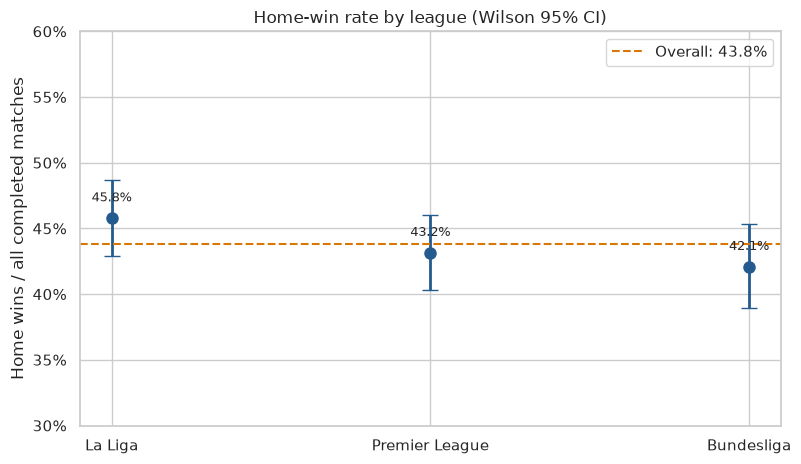

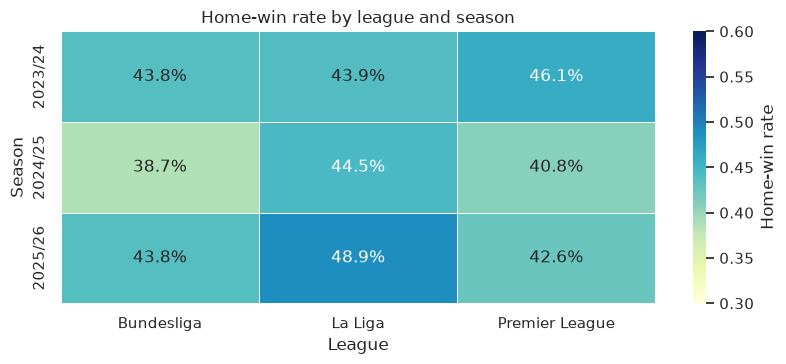

In [3]:
def wilson_interval(successes, n, z=1.959963984540054):
    """Wilson score interval for a binomial proportion."""
    if n == 0:
        return np.nan, np.nan
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denom
    half = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / denom
    return center - half, center + half

league_summary = (analysis.groupby("liga", observed=True)
    .agg(matches=("match_id", "size"), home_win_rate=("heim_sieg", "mean"),
         goals_per_match=("tore_total", "mean"))
    .reset_index())
intervals = league_summary.apply(
    lambda r: wilson_interval(round(r.home_win_rate*r.matches), int(r.matches)), axis=1
)
league_summary[["ci_low", "ci_high"]] = pd.DataFrame(intervals.tolist(), index=league_summary.index)
league_summary = league_summary.sort_values("home_win_rate", ascending=False)
display(league_summary.round(3))

fig, ax = plt.subplots(figsize=(8.2, 4.8))
x = np.arange(len(league_summary))
y = league_summary["home_win_rate"].to_numpy()
lo = y - league_summary["ci_low"].to_numpy()
hi = league_summary["ci_high"].to_numpy() - y
ax.errorbar(x, y, yerr=[lo, hi], fmt="o", markersize=8, capsize=6,
            color="#245b8f", ecolor="#245b8f", linewidth=2)
for xi, yi, n in zip(x, y, league_summary["matches"]):
    ax.annotate(f"{yi:.1%}", (xi, yi), xytext=(0, 12),
                textcoords="offset points", ha="center", fontsize=9)
overall_rate = analysis["heim_sieg"].mean()
ax.axhline(overall_rate, color="#d97706", linestyle="--", linewidth=1.5,
           label=f"Overall: {overall_rate:.1%}")
ax.set(xticks=x, xticklabels=league_summary["liga"], ylim=(0.30, 0.60),
       ylabel="Home wins / all completed matches", title="Home-win rate by league (Wilson 95% CI)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=True, loc="best")
fig.tight_layout()
plt.show()

season_league = analysis.pivot_table(index="saison", columns="liga", values="heim_sieg", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(8.3, 3.8))
sns.heatmap(season_league, annot=True, fmt=".1%", cmap="YlGnBu", vmin=0.30, vmax=0.60,
            linewidths=0.6, linecolor="white", cbar_kws={"label": "Home-win rate"}, ax=ax)
ax.set(title="Home-win rate by league and season", xlabel="League", ylabel="Season")
fig.tight_layout()
plt.show()


### Weather distributions

Rainfall has many zero values, so a single overlaid histogram hides useful detail. The plots separate the proportion of matches with any recorded rain from rainfall amounts among rainy matches. Temperature is shown by outcome with a common scale. These are descriptive plots, not evidence of causality.


,resultat,label,matches,rain_rate,ci_low,ci_high
0,H,Home win,1400,0.294,0.270,0.318
1,D,Draw,809,0.284,0.254,0.316
2,A,Away win,988,0.248,0.222,0.276


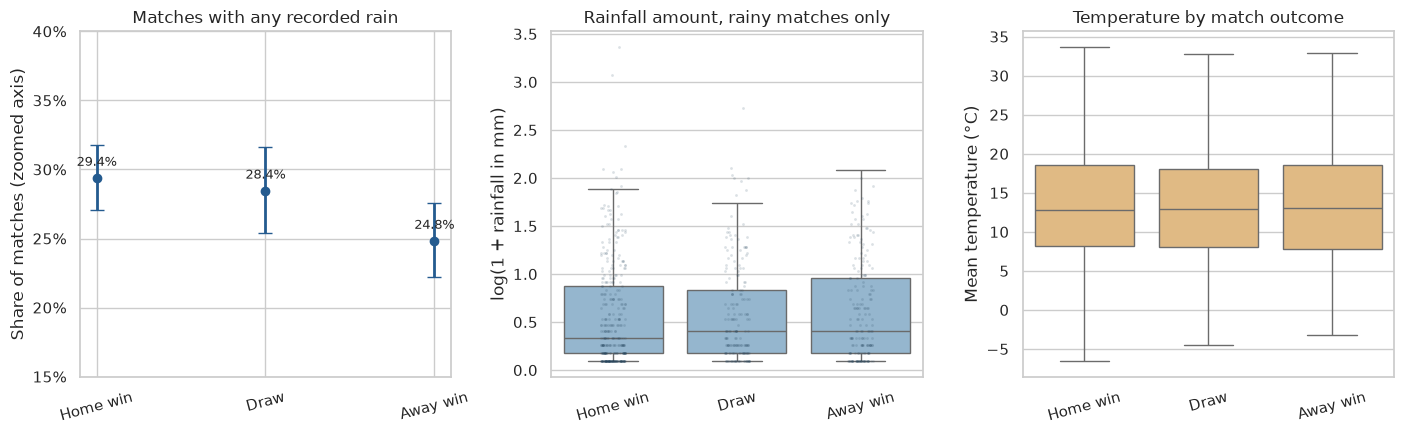

In [4]:
outcome_order = [x for x in ["H", "D", "A"] if x in set(analysis["resultat"])]
outcome_labels = {"H": "Home win", "D": "Draw", "A": "Away win"}
rain_rows = []
for result in outcome_order:
    g = analysis.loc[analysis["resultat"].eq(result)]
    successes = int(g["regen_vorhanden"].sum())
    low, high = wilson_interval(successes, len(g))
    rain_rows.append({"resultat": result, "label": outcome_labels.get(result, result),
                      "matches": len(g), "rain_rate": successes/len(g), "ci_low": low, "ci_high": high})
rain_summary = pd.DataFrame(rain_rows)
display(rain_summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.5))
x = np.arange(len(rain_summary))
y = rain_summary["rain_rate"].to_numpy()
axes[0].errorbar(x, y, yerr=[y-rain_summary["ci_low"], rain_summary["ci_high"]-y],
                 fmt="o", capsize=5, color="#245b8f", linewidth=2)
axes[0].set(xticks=x, xticklabels=[outcome_labels.get(v, v) for v in rain_summary["resultat"]],
            ylim=(0.15, 0.40), ylabel="Share of matches (zoomed axis)", title="Matches with any recorded rain")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for xi, yi in zip(x, y):
    axes[0].annotate(f"{yi:.1%}", (xi, yi), xytext=(0, 9), textcoords="offset points",
                     ha="center", fontsize=9)

rainy = analysis.loc[analysis["regen_vorhanden"]].copy()
rainy["log1p_rainfall"] = np.log1p(rainy["regen_summe"])
if len(rainy):
    sns.boxplot(data=rainy, x="resultat", y="log1p_rainfall", order=outcome_order,
                showfliers=False, color="#8bb7d8", ax=axes[1])
    sns.stripplot(data=rainy.sample(min(700, len(rainy)), random_state=RANDOM_STATE),
                  x="resultat", y="log1p_rainfall", order=outcome_order,
                  color="#24445c", alpha=0.16, size=2, ax=axes[1])
axes[1].set(xticks=np.arange(len(outcome_order)), xticklabels=[outcome_labels.get(v,v) for v in outcome_order],
            xlabel="", ylabel="log(1 + rainfall in mm)", title="Rainfall amount, rainy matches only")

sns.boxplot(data=analysis, x="resultat", y="temperatur_mittel", order=outcome_order,
            showfliers=False, color="#efbd75", ax=axes[2])
axes[2].set(xticks=np.arange(len(outcome_order)), xticklabels=[outcome_labels.get(v,v) for v in outcome_order],
            xlabel="", ylabel="Mean temperature (°C)", title="Temperature by match outcome")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
plt.show()


## 3. Statistical tests

The chi-square test assesses whether the H/D/A outcome distribution differs by league. Kruskal–Wallis tests compare temperature and rainfall distributions across outcomes; this avoids relying on normally distributed weather measurements. We report effect sizes where straightforward. Because several exploratory tests are run, Holm-adjusted p-values are shown alongside raw p-values. A non-significant p-value is not proof that the groups are identical.


In [5]:
# League by outcome: chi-square test and Cramer's V
contingency = pd.crosstab(analysis["liga"], analysis["resultat"]).reindex(columns=["H", "D", "A"], fill_value=0)
chi2, p_chi, dof, expected = chi2_contingency(contingency)
n = contingency.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * min(contingency.shape[0]-1, contingency.shape[1]-1)))
print("League × outcome counts:")
display(contingency)
print(f"Chi-square({dof}) = {chi2:.3f}, p = {p_chi:.4f}; Cramer's V = {cramers_v:.3f}")

# Weather by result category: non-parametric tests
groups_temp = [g["temperatur_mittel"].dropna().to_numpy() for _, g in analysis.groupby("resultat")]
groups_rain = [g["regen_summe"].dropna().to_numpy() for _, g in analysis.groupby("resultat")]
h_temp, p_temp = kruskal(*groups_temp)
h_rain, p_rain = kruskal(*groups_rain)
print(f"Kruskal-Wallis temperature: H = {h_temp:.3f}, p = {p_temp:.4f}")
print(f"Kruskal-Wallis rainfall:     H = {h_rain:.3f}, p = {p_rain:.4f}")

# Compare rain occurrence across outcomes as a separate, interpretable question.
rain_table = pd.crosstab(analysis["resultat"], analysis["regen_vorhanden"]).reindex(index=["H","D","A"], columns=[False,True], fill_value=0)
chi2_rain, p_rain_occ, dof_rain, _ = chi2_contingency(rain_table)
v_rain = np.sqrt(chi2_rain / (rain_table.to_numpy().sum() * min(rain_table.shape[0]-1, rain_table.shape[1]-1)))
print(f"Rain occurrence × outcome: Chi-square({dof_rain}) = {chi2_rain:.3f}, p = {p_rain_occ:.4f}; Cramer's V = {v_rain:.3f}")

# Holm correction across the four exploratory tests above.
p_values = {"League × outcome": p_chi, "Temperature by outcome": p_temp,
            "Rainfall amount by outcome": p_rain, "Rain occurrence × outcome": p_rain_occ}
def holm_adjust(values):
    items = list(values.items())
    order = np.argsort([v for _, v in items])
    adjusted = np.empty(len(items), dtype=float)
    running_max = 0.0
    m = len(items)
    for rank, idx in enumerate(order):
        candidate = (m-rank) * items[idx][1]
        running_max = max(running_max, candidate)
        adjusted[idx] = min(running_max, 1.0)
    return {items[i][0]: adjusted[i] for i in range(m)}
adjusted = holm_adjust(p_values)
test_summary = pd.DataFrame({"raw_p": p_values, "holm_adjusted_p": adjusted})
display(test_summary.round(4))


League × outcome counts:


resultat,H,D,A
liga,,,
Bundesliga,386,233,298
La Liga,522,297,321
Premier League,492,279,369


Chi-square(4) = 6.640, p = 0.1562; Cramer's V = 0.032
Kruskal-Wallis temperature: H = 0.017, p = 0.9914
Kruskal-Wallis rainfall:     H = 5.299, p = 0.0707
Rain occurrence × outcome: Chi-square(2) = 6.289, p = 0.0431; Cramer's V = 0.044


,raw_p,holm_adjusted_p
League × outcome,0.1562,0.3123
Temperature by outcome,0.9914,0.9914
Rainfall amount by outcome,0.0707,0.2121
Rain occurrence × outcome,0.0431,0.1724


## 4. Models and out-of-season evaluation

We evaluate on the **latest season only** and train on all earlier seasons. This is a chronological holdout: it better reflects applying a model to a future season than a random split, though it gives only one test season. Every model is evaluated on the same matches.

Two related targets are analyzed:

1. **H / D / A classification:** compares a league-and-team context model with a model that adds weather and weather × league terms.
2. **Home win / no home win:** directly addresses home advantage. Draws and away wins are both coded as “no home win.”

Because the held-out season is unseen during training, its season label is not used as a predictor. Team identities are retained, so the forecast concerns later matches involving mostly familiar teams; it is not a test on entirely new clubs.

Home and away team IDs are included as categorical context variables to partially account for persistent team differences. They are not a complete measure of team strength, and new/previously unseen teams are handled as unknown categories.


In [6]:
def season_start(value):
    match = re.search(r"(20\d{2})", str(value))
    return int(match.group(1)) if match else -1
season_order = sorted(analysis["saison"].unique(), key=season_start)
if len(season_order) < 2:
    raise ValueError("At least two seasons are required for a temporal train/test split.")
test_season = season_order[-1]
train = analysis.loc[analysis["saison"].ne(test_season)].copy()
test = analysis.loc[analysis["saison"].eq(test_season)].copy()
print(f"Training seasons: {[s for s in season_order if s != test_season]}")
print(f"Test season: {test_season} | train n={len(train):,} | test n={len(test):,}")
if train.empty or test.empty:
    raise ValueError("Temporal split produced an empty train or test set.")

weather_base = ["regen_log", "temperatur_mittel", "wind_mittel"]
# Scale weather using training-season statistics only. Main effects and interactions
# then share a common unit: one standard deviation of the training weather variable.
weather_training_values = pd.DataFrame({
    "regen_log": np.log1p(train["regen_summe"].clip(lower=0)),
    "temperatur_mittel": train["temperatur_mittel"].astype(float),
    "wind_mittel": train["wind_mittel"].astype(float),
})
weather_means = weather_training_values.mean()
weather_stds = weather_training_values.std().replace(0, 1)
reference_league = "Premier League" if "Premier League" in set(analysis["liga"]) else sorted(analysis["liga"].unique())[0]
print(f"Reference league for weather interactions: {reference_league}")

def make_features(frame, use_weather=False):
    x = frame[["liga", "heim_id", "gast_id"]].copy()
    x["liga"] = x["liga"].astype(str)
    x["heim_id"] = x["heim_id"].astype(str)
    x["gast_id"] = x["gast_id"].astype(str)
    if use_weather:
        raw_weather = pd.DataFrame(index=frame.index)
        raw_weather["regen_log"] = np.log1p(frame["regen_summe"].clip(lower=0))
        raw_weather["temperatur_mittel"] = frame["temperatur_mittel"].astype(float)
        raw_weather["wind_mittel"] = frame["wind_mittel"].astype(float)
        for weather in weather_base:
            x[weather] = (raw_weather[weather] - weather_means[weather]) / weather_stds[weather]
            # Reference-league slope is the main effect; these add deviations for other leagues.
            for league in sorted(analysis["liga"].unique()):
                if league == reference_league:
                    continue
                safe = re.sub(r"[^a-z0-9]+", "_", league.lower()).strip("_")
                x[f"{weather}_x_{safe}"] = x[weather] * frame["liga"].eq(league).astype(float)
    return x

cat_cols = ["liga", "heim_id", "gast_id"]
# Separate, stable preprocessing definitions for base and weather models.
def build_pipeline(numeric_cols):
    transformers = [("categorical", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols)]
    if numeric_cols:
        transformers.append(("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
        ]), numeric_cols))
    prep = ColumnTransformer(transformers, remainder="drop")
    return Pipeline([("preprocess", prep),
                     ("model", LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"))])

X_train_base = make_features(train, use_weather=False)
X_test_base = make_features(test, use_weather=False)
X_train_weather = make_features(train, use_weather=True)
X_test_weather = make_features(test, use_weather=True)
numeric_weather_cols = [c for c in X_train_weather.columns if c not in cat_cols]


Training seasons: ['2023/24', '2024/25']
Test season: 2025/26 | train n=2,131 | test n=1,066
Reference league for weather interactions: Premier League


In [7]:
# Multiclass outcome models
y_train_hda = train["resultat"]
y_test_hda = test["resultat"]
hda_models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "League + home/away teams": build_pipeline([]),
    "Context + weather × league": build_pipeline(numeric_weather_cols),
}
X_for_model = {
    "Majority baseline": (np.zeros((len(train), 1)), np.zeros((len(test), 1))),
    "League + home/away teams": (X_train_base, X_test_base),
    "Context + weather × league": (X_train_weather, X_test_weather),
}
hda_rows = []
fitted_hda = {}
for name, model in hda_models.items():
    Xtr, Xte = X_for_model[name]
    model.fit(Xtr, y_train_hda)
    pred = model.predict(Xte)
    prob = model.predict_proba(Xte)
    fitted_hda[name] = (model, pred, prob)
    hda_rows.append({
        "Model": name, "Accuracy": accuracy_score(y_test_hda, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test_hda, pred),
        "Macro-F1": f1_score(y_test_hda, pred, average="macro"),
    })
hda_results = pd.DataFrame(hda_rows).set_index("Model")
display(hda_results.round(3))


,Accuracy,Balanced accuracy,Macro-F1
Model,,,
Majority baseline,0.452,0.333,0.208
League + home/away teams,0.454,0.453,0.447
Context + weather × league,0.460,0.459,0.452


### H / D / A model diagnostics

Accuracy can hide poor performance on less frequent outcomes. Macro-F1 and balanced accuracy give each class more equal weight. Log loss evaluates the quality of predicted probabilities (lower is better). Always compare these scores with the baseline and discuss the class-level report.


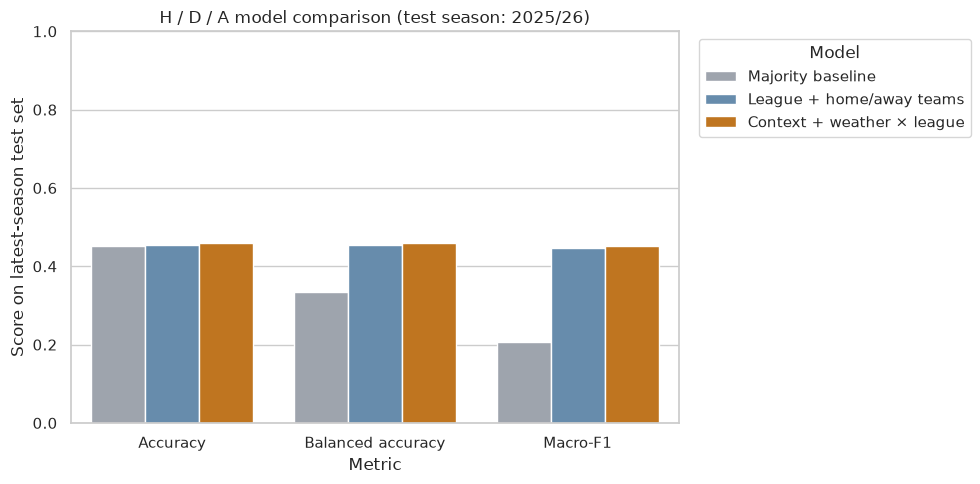

Classification report for the weather model:
              precision    recall  f1-score   support

    Home win       0.62      0.45      0.52       482
        Draw       0.32      0.41      0.36       272
    Away win       0.45      0.52      0.48       312

    accuracy                           0.46      1066
   macro avg       0.46      0.46      0.45      1066
weighted avg       0.49      0.46      0.47      1066



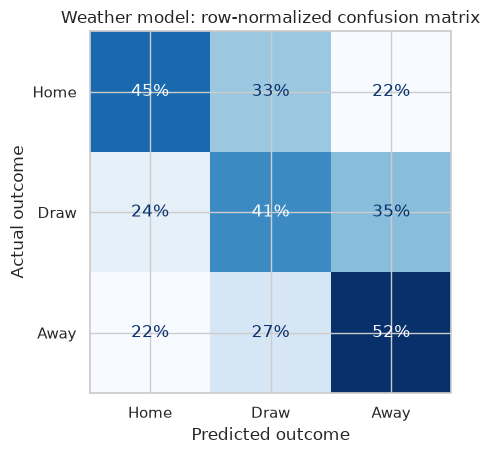

In [8]:
metric_cols = ["Accuracy", "Balanced accuracy", "Macro-F1"]
plot_hda = hda_results[metric_cols].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_hda, x="Metric", y="Score", hue="Model", ax=ax, palette=["#9ca3af", "#5b8db8", "#d97706"] )
ax.set(ylim=(0, 1), ylabel="Score on latest-season test set", title=f"H / D / A model comparison (test season: {test_season})")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

weather_model, hda_pred, hda_prob = fitted_hda["Context + weather × league"]
print("Classification report for the weather model:")
print(classification_report(y_test_hda, hda_pred, labels=["H", "D", "A"],
                            target_names=["Home win", "Draw", "Away win"], zero_division=0))
fig, ax = plt.subplots(figsize=(5.5, 4.7))
ConfusionMatrixDisplay.from_predictions(
    y_test_hda, hda_pred, labels=["H", "D", "A"], display_labels=["Home", "Draw", "Away"],
    normalize="true", values_format=".0%", cmap="Blues", ax=ax, colorbar=False
)
ax.set(title="Weather model: row-normalized confusion matrix", xlabel="Predicted outcome", ylabel="Actual outcome")
fig.tight_layout()
plt.show()


### Direct home-advantage model

This binary model predicts a home win versus no home win. It is an additional view of home advantage, not a replacement for the three-outcome model. Report the test metrics and the weather coefficients together; coefficient magnitudes are associations in a regularized model and are **not** significance tests or causal effects.


In [9]:
y_train_home = train["heim_sieg"]
y_test_home = test["heim_sieg"]
home_models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "League + home/away teams": build_pipeline([]),
    "Context + weather × league": build_pipeline(numeric_weather_cols),
}
home_x = {
    "Majority baseline": (np.zeros((len(train),1)), np.zeros((len(test),1))),
    "League + home/away teams": (X_train_base, X_test_base),
    "Context + weather × league": (X_train_weather, X_test_weather),
}
home_rows = []
fitted_home = {}
for name, model in home_models.items():
    Xtr, Xte = home_x[name]
    model.fit(Xtr, y_train_home)
    pred = model.predict(Xte)
    prob = model.predict_proba(Xte)[:, list(model.classes_).index(1)]
    fitted_home[name] = (model, pred, prob)
    home_rows.append({
        "Model": name, "Accuracy": accuracy_score(y_test_home, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test_home, pred),
        "F1 (home win)": f1_score(y_test_home, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_home, prob),
    })
home_results = pd.DataFrame(home_rows).set_index("Model")
display(home_results.round(3))


,Accuracy,Balanced accuracy,F1 (home win),ROC-AUC
Model,,,,
Majority baseline,0.548,0.500,0.000,0.500
League + home/away teams,0.645,0.641,0.605,0.695
Context + weather × league,0.641,0.637,0.600,0.690


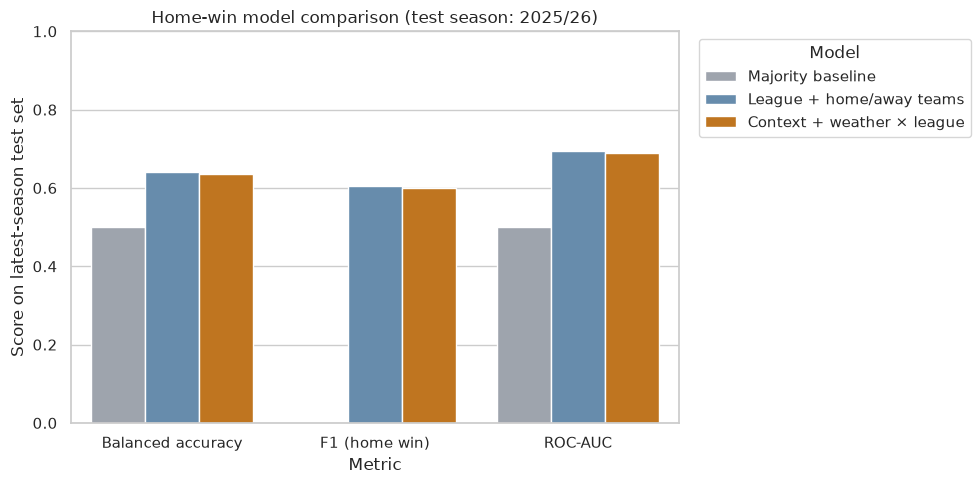

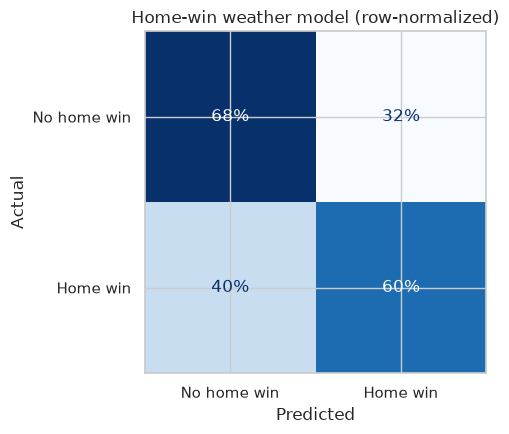

,League,Weather feature,Log-odds change per training SD,Odds ratio per training SD
0,Bundesliga,log(1 + rainfall),-0.015,0.985
1,Bundesliga,Temperature,-0.082,0.921
2,Bundesliga,Wind speed,-0.014,0.986
3,La Liga,log(1 + rainfall),0.049,1.050
4,La Liga,Temperature,-0.034,0.967
5,La Liga,Wind speed,0.118,1.125
6,Premier League,log(1 + rainfall),-0.069,0.934
7,Premier League,Temperature,-0.088,0.916
8,Premier League,Wind speed,-0.052,0.949


In [10]:
# Plot binary home-win evaluation on a common 0–1 scale.
home_plot = home_results[["Balanced accuracy", "F1 (home win)", "ROC-AUC"]].reset_index().melt(
    id_vars="Model", var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=home_plot, x="Metric", y="Score", hue="Model", ax=ax, palette=["#9ca3af", "#5b8db8", "#d97706"])
ax.set(ylim=(0, 1), ylabel="Score on latest-season test set", title=f"Home-win model comparison (test season: {test_season})")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

model, home_pred, home_prob = fitted_home["Context + weather × league"]
fig, ax = plt.subplots(figsize=(5.2, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test_home, home_pred, labels=[0,1],
    display_labels=["No home win", "Home win"], normalize="true", values_format=".0%", cmap="Blues", ax=ax, colorbar=False)
ax.set(title="Home-win weather model (row-normalized)", xlabel="Predicted", ylabel="Actual")
fig.tight_layout()
plt.show()

# League-specific weather slopes from the regularized binary model.
# Main effect = Premier League slope; an interaction adds the deviation for another league.
# Odds ratios are per one training-set SD of the corresponding weather variable.
# These descriptive model parameters have no p-values and are not causal effects.
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coef = model.named_steps["model"].coef_[0]
coef_by_name = dict(zip(feature_names, coef))
weather_readable = {"regen_log": "log(1 + rainfall)", "temperatur_mittel": "Temperature", "wind_mittel": "Wind speed"}
effect_rows = []
for league in sorted(analysis["liga"].unique()):
    for weather in weather_base:
        slope = coef_by_name.get(f"numeric__{weather}", 0.0)
        if league != reference_league:
            safe = re.sub(r"[^a-z0-9]+", "_", league.lower()).strip("_")
            slope += coef_by_name.get(f"numeric__{weather}_x_{safe}", 0.0)
        effect_rows.append({"League": league, "Weather feature": weather_readable[weather],
                            "Log-odds change per training SD": slope,
                            "Odds ratio per training SD": np.exp(slope)})
weather_effects = pd.DataFrame(effect_rows)
display(weather_effects.round(3))


## 5. Exploratory weather clusters (K-means)

K-means is an additional descriptive analysis. Rainfall is log-transformed to reduce its strong right skew; all three weather variables are then standardized. We compare silhouette scores for k = 2–5 and use the best-scoring k in this range for the profile summary. Cluster labels are descriptive, and cluster differences do not imply an effect of weather.


,k,silhouette
0,2,0.467
1,3,0.319
2,4,0.353
3,5,0.305


Selected k=2, the highest silhouette score among k=2–5.


,matches,rainfall_mm,temperature_c,wind_kmh,profile
cluster_id,,,,,
1,378,2.32,12.46,18.19,Wettest
0,2819,0.05,13.68,11.86,Driest


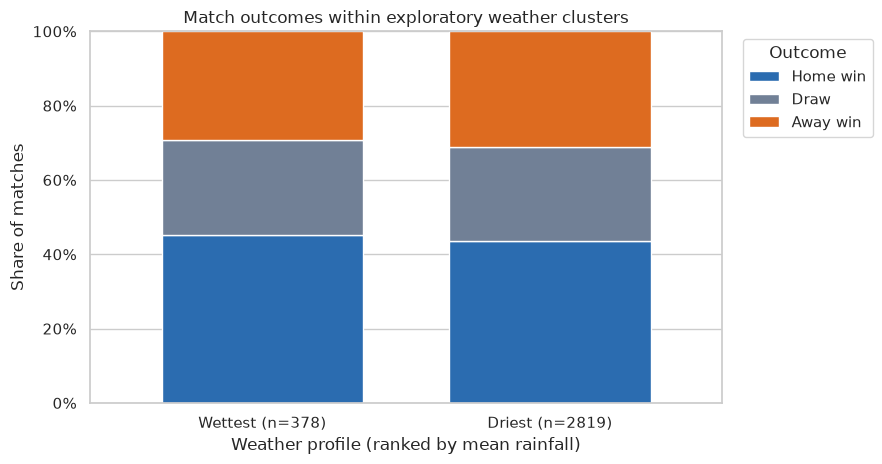

resultat,H,D,A
Wettest (n=378),0.452,0.254,0.294
Driest (n=2819),0.436,0.253,0.311


In [11]:
cluster_cols = ["regen_summe", "temperatur_mittel", "wind_mittel"]
cluster_data = analysis[cluster_cols].copy()
cluster_data["regen_log"] = np.log1p(cluster_data["regen_summe"].clip(lower=0))
cluster_data = cluster_data[["regen_log", "temperatur_mittel", "wind_mittel"]]
cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(cluster_data)

silhouette_rows = []
for k in range(2, 6):
    km_test = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels_test = km_test.fit_predict(cluster_scaled)
    silhouette_rows.append({"k": k, "silhouette": silhouette_score(cluster_scaled, labels_test)})
silhouette_table = pd.DataFrame(silhouette_rows)
display(silhouette_table.round(3))

best_k = int(silhouette_table.loc[silhouette_table["silhouette"].idxmax(), "k"])
print(f"Selected k={best_k}, the highest silhouette score among k=2–5.")
km = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
analysis["cluster_id"] = km.fit_predict(cluster_scaled)
cluster_profile = analysis.groupby("cluster_id", observed=True).agg(
    matches=("match_id", "size"), rainfall_mm=("regen_summe", "mean"),
    temperature_c=("temperatur_mittel", "mean"), wind_kmh=("wind_mittel", "mean")
).round(2)
# Give readable rank labels based on the observed mean rainfall.
ranked_ids = cluster_profile["rainfall_mm"].sort_values(ascending=False).index.tolist()
if len(ranked_ids) == 2:
    readable_names = ["Wettest", "Driest"]
else:
    readable_names = ["Wettest"] + [f"Intermediate rainfall {i}" for i in range(1, len(ranked_ids)-1)] + ["Driest"]
rank_names = dict(zip(ranked_ids, readable_names))
cluster_profile["profile"] = [rank_names[i] for i in cluster_profile.index]
display(cluster_profile.sort_values("rainfall_mm", ascending=False))

cluster_result = (pd.crosstab(analysis["cluster_id"], analysis["resultat"], normalize="index")
                  .reindex(columns=["H", "D", "A"], fill_value=0))
cluster_result.index = [f"{rank_names[i]} (n={int(cluster_profile.loc[i, 'matches'])})" for i in cluster_result.index]
cluster_result = cluster_result.loc[[f"{rank_names[i]} (n={int(cluster_profile.loc[i, 'matches'])})" for i in ranked_ids]]
ax = cluster_result.rename(columns={"H":"Home win", "D":"Draw", "A":"Away win"}).plot(
    kind="bar", stacked=True, figsize=(9, 4.8), color=["#2b6cb0", "#718096", "#dd6b20"], width=0.7)
ax.set(ylim=(0,1), xlabel="Weather profile (ranked by mean rainfall)", ylabel="Share of matches",
       title="Match outcomes within exploratory weather clusters")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Outcome", bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout()
plt.show()
display(cluster_result.round(3))


## 6. Findings and limitations

Use the values generated above to complete the final interpretation. A strong conclusion distinguishes **descriptive differences**, **statistical evidence**, and **out-of-season predictive performance**. Do not claim that weather causes match outcomes.

### Checklist for the report

- State the number of included matches and the excluded awarded match(es).
- Compare home-win rates with confidence intervals; do not describe small differences as important without evidence.
- Report test statistics, p-values, and effect sizes where available.
- Compare all models on the same latest-season test set. Report Macro-F1 / balanced accuracy as well as accuracy; mention the baseline.
- State whether adding weather improves held-out performance, and whether the change is practically meaningful.
- Explain that team strength, line-ups, injuries, referee, attendance, pitch, and tactical variables are not fully controlled.
- Weather is estimated at the city/stadium location and aggregated around kick-off; measurement error and the limited number of leagues/seasons constrain conclusions.
- K-means is exploratory; cluster IDs are arbitrary and the silhouette score helps assess separation, not prove that the groups are objectively real.

### AI-use reflection

Document which AI tools helped draft or debug the notebook, what you checked yourself, what was useful, and what did not work. Verify all interpretations against the executed outputs before submission.
